# Causal observer access and deterministic recovery

How much of a diary can an observer recover when the radiation state stays fixed but access to early radiation changes? This notebook follows that question from the received registers to information bounds and deterministic recovery. A collection mask names the carriers that arrive together. Its readable classical flag lets a decoder choose an operation for that outcome. Completely positive and trace-preserving (CPTP) operations describe physical deterministic processing, including on inputs entangled with the untouched reference. Every outcome contributes to the final score. It then examines how receiving carriers together changes the result, even when each carrier's individual access probability stays the same.

## Getting started

Run the cells in order. The notebook reads information tables for 32 source states, propagated waveforms, detector probabilities, and subset entropies from `inputs/`. It recalculates the access results and saves figures and tables in `outputs/runs/<run>/observer`. Allow up to two minutes on a standard CPU.

These supplied arrays let you explore observer access without first running the propagation calculation. For the full source-to-detector calculation, open `Upstream_Regeneration.ipynb`. That notebook generates source states, solves scattering, constructs waveforms, and integrates detector probabilities before comparing them with the reference arrays. Its numerical conventions specify the random draws, scattering solver, packet integration, and detector settings. The detector recurrence here provides a separate integration check.

## Source and accessible registers

The diary qubit $A$ is Bell-entangled with an inaccessible reference $Q$. Five black-hole qubits $B$ are maximally entangled with early radiation $E$. A seeded Haar unitary maps $AB$ to one remaining qubit $C$ and five emitted qubits $D$. Neither observer controls $Q$ or $C$. Five dual-rail carriers propagate as independent massless scalar channels. The comparisons change early-radiation possession while holding the source, late detector, and lifetime fixed.

The parameters are $r=20M$, $x_0=M\omega=0.16$, fractional Gaussian width 0.20, aperture 0.72, efficiency 0.88, $T=120M$, and input peaks $(28,40,52,64,76)M$. The two-port cavity has $M\kappa=0.515$, equal ports, $M\omega_c=0.16/\sqrt{0.9}$, and initially empty memory. Accessible late registers include accumulated detected output and current cavity occupation. The reflected port is inaccessible.

In [1]:
from pathlib import Path
import os, datetime, json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
sys.path.insert(0, str(Path('code').resolve()))
OUTPUT = Path('outputs/runs') / os.environ.get('ODER_RUN_NAME', datetime.datetime.now().strftime('%Y%m%d_%H%M%S')) / 'observer'
OUTPUT.mkdir(parents=True, exist_ok=True)
pd.set_option('display.precision', 10)

from scipy.optimize import linprog, brentq
from cavity import mask_weights, hp_value, root_bisection, qec_value, exponential_cavity
inputs = np.load('inputs/closure_reproduction_inputs.npz')
joint = np.load('inputs/hp_joint_information.npy')
bits = np.array([[(m >> j) & 1 for m in range(32)] for j in range(5)])
p = inputs['observer_carriers'][-1]
late_weights = mask_weights(p)
tables = np.einsum('s,nst->nt', late_weights, joint)
assert joint.shape == (32,32,32)
assert np.max(abs(joint.mean(axis=0)-inputs['mean_information'])) < 1e-12
assert np.max(abs(joint[0]-inputs['first_seed_information'])) < 1e-12
assert abs(late_weights.sum()-1) < 1e-12
assert joint.min() >= -2e-10 and joint.max() <= 1+2e-10
violations=[]
for axis in [1,2]:
    for mask in range(32):
        for j in range(5):
            if not mask & (1<<j):
                violations.append(np.max(np.take(joint,mask,axis)-np.take(joint,mask|(1<<j),axis)))
assert max(violations) < 2e-10
assert np.max(abs(joint[:,0,:])) < 2e-10
display(pd.DataFrame({'carrier':np.arange(1,6),'late_probability':p}))

,carrier,late_probability
0,1,0.4281480462
1,2,0.4470597491
2,3,0.4503704444
3,4,0.4506100730
4,5,0.4494704592


## Statewise information and the recovery score

For subset masks $S,T$, the normalized reference information is $J_s(S,T)=I(Q:D_SE_T)/2$, measured in bits with $S(Q)=1$. Independent mask weights account for each retained or erased carrier. The observer receives flags identifying the available registers. These flags are independent of the diary, so their Shannon entropy cancels in mutual information.

We evaluate each of the 32 source states separately. Averaging those values gives mean statewise information; taking the information of an unlabeled mixture would be a different calculation.

The recovery score is

$$F_{\rm opt}(X)=\max_{\mathcal D}\langle\Phi_2|(\mathrm{id}\otimes\mathcal D)(\rho_{QX})|\Phi_2\rangle.$$

It is the Bell overlap, or squared fidelity, averaged over flags. The maximum ranges over deterministic CPTP decoders on the specified registers, with unrestricted computation and independent ancillas. Each decoder may depend on the known source. An upper bound therefore constrains every allowed decoder; a lower bound establishes the existence of a suitable decoder for each source. These bounds describe optimal deterministic recovery, rather than a heralded success probability or the performance of an arbitrary decoder.

We calculate the analytic bounds $2^{2e-2}\leq F_{\rm opt}\leq b(e)$, where $D_{\mathrm{bin},2}(b\|1/4)=2e$ on $[1/4,1]$. The upper bound requires a scalar root solve. No decoder is constructed or numerically optimized in this notebook.

There are two useful orders of calculation. An aggregate certificate first averages information over flags and then applies the recovery inequality. A branch-resolved certificate applies the inequality to each readable outcome before averaging its fidelity bound. The latter preserves information in the collection record and can give a stronger certificate. Both procedures are retained in the manuscript, including the aggregate propagation-control tables. Neither procedure constructs a decoder.

In [2]:
wg = mask_weights(inputs['global_carriers'][-1])
e_global = np.einsum('s,ns->n', wg, joint[:,:,31])
def binary_divergence(f):
    if f == 1: return 2.
    return f*np.log2(f/.25)+(1-f)*np.log2((1-f)/.75)
ceilings = np.array([brentq(lambda f: binary_divergence(f)-2*e,.25,1.) for e in tables[:,0]])
floors = 2**(2*tables[:,31]-2)
roots = np.array([root_bisection(j,p) for j in joint])
statewise = pd.DataFrame({'seed':2026082100+np.arange(32), 'global_e':e_global,
    'no_early_e':tables[:,0], 'full_early_e':tables[:,31], 'alpha_c':roots,
    'no_early_fidelity_ceiling':ceilings,'full_early_fidelity_floor':floors})
statewise.to_csv(OUTPUT/'statewise_recovery.csv',index=False)
display(statewise)
fixed=pd.DataFrame({'registers':['Global transmitted','No early radiation','All early radiation'],
    'e':[e_global[0],tables[0,0],tables[0,31]]})
fixed['coherent_information_bits']=2*fixed.e-1
display(fixed)
upper,lower=ceilings.max(),floors.min()
assert upper < .3572 and lower > .8155
assert np.all(tables[:,0]<.5) and np.all(tables[:,31]>.5)
assert np.all(tables[:,31] <= e_global+2e-10)
# Half a final printed decimal is the rounding tolerance, not a model tolerance.
np.testing.assert_allclose(fixed.e,[.97567551,.01788180,.85608138],rtol=0,atol=5.1e-9)
np.testing.assert_allclose([e_global.mean(),tables[:,0].mean(),tables[:,31].mean()],
    [.97658883,.01887552,.85685442],rtol=0,atol=5.1e-9)
np.testing.assert_allclose([upper,lower],[.3571621676,.8155976741],rtol=0,atol=5.1e-11)
np.testing.assert_allclose([roots[0],roots.min(),roots.max()],
    [.66142806,.65983217,.66267574],rtol=0,atol=5.1e-9)
print(f'Uniform fidelity ceiling {upper:.10f}; floor {lower:.10f}')
archived=pd.read_csv('inputs/hp_seed_access_robustness.csv')
assert np.array_equal(statewise.seed,archived.seed)
np.testing.assert_allclose(statewise[['global_e','no_early_e','full_early_e','alpha_c']],
    archived[['eQ','ei_alpha0','ei_alpha1','alpha_c']],rtol=0,atol=1e-12)
np.testing.assert_allclose([tables[:,0].max(),tables[:,31].min()],
    [.02041190,.85296478],rtol=0,atol=5.1e-9)


from recovery_certificates import statewise as recovery_certificates
resolved=pd.DataFrame(recovery_certificates(joint,p))
display(resolved[['source_index','no_early_branch_upper','full_early_branch_lower']])
resolved.to_csv(OUTPUT/'branch_and_aggregate_certificates.csv',index=False)
branch_ceiling=resolved.no_early_branch_upper.max()
branch_floor=resolved.full_early_branch_lower.min()
assert branch_ceiling < .3308 and branch_floor > .8476
print('Branch-resolved uniform ceiling and floor:',format(branch_ceiling,'.15g'),format(branch_floor,'.15g'))


,seed,global_e,no_early_e,full_early_e,alpha_c,no_early_fidelity_ceiling,full_early_fidelity_floor
0,2026082100,0.9756755136,0.0178818014,0.8560813763,0.6614280604,0.3500827631,0.8191290998
1,2026082101,0.9764133495,0.0188010544,0.8570362228,0.6610893373,0.3527065337,0.8202140976
2,2026082102,0.9755503091,0.0204119044,0.8560073753,0.6617771751,0.3571621676,0.8190450720
3,2026082103,0.9762417401,0.0188909186,0.8562823431,0.6613119860,0.3529597396,0.8193573403
4,2026082104,0.9764987364,0.0195316655,0.8564431531,0.6611759632,0.3547488921,0.8195400200
5,2026082105,0.9766255572,0.0182631067,0.8570343365,0.6614012793,0.3511786643,0.8202119527
6,2026082106,0.9762025346,0.0193410772,0.8570320723,0.6622254146,0.3542196505,0.8202093783
7,2026082107,0.9763258194,0.0197457520,0.8559071400,0.6609725843,0.3553404844,0.8189312689
8,2026082108,0.9773379270,0.0182278092,0.8591748341,0.6605585512,0.3510776738,0.8226494313
9,2026082109,0.9769021521,0.0193258974,0.8569531695,0.6615942370,0.3541773922,0.8201196666


,registers,e,coherent_information_bits
0,Global transmitted,0.9756755136,0.9513510273
1,No early radiation,0.0178818014,-0.9642363972
2,All early radiation,0.8560813763,0.7121627525


Uniform fidelity ceiling 0.3571621676; floor 0.8155976741


,source_index,no_early_branch_upper,full_early_branch_lower
0,0,0.3225278678,0.8510928259
1,1,0.3259832057,0.8522463426
2,2,0.3307184460,0.8509723438
3,3,0.3258619925,0.8514220544
4,4,0.3272956639,0.8516935300
5,5,0.3233572458,0.8523076558
6,6,0.3272017701,0.8522885864
7,7,0.3288835880,0.8510605784
8,8,0.3246498379,0.8547121187
9,9,0.3257994570,0.8522300540


Branch-resolved uniform ceiling and floor: 0.330718445960354 0.847608364687859


The aggregate certificates give a ceiling below 0.3572 without early radiation and a floor above 0.8155 with it. Keeping each collection outcome resolved gives the stronger uniform certificates 0.3308 and 0.8476. Each ceiling is rounded upward and each floor downward. The two procedures use the same states and detector; their order of averaging differs.

## Access probability does not specify joint access

Independent access and all-or-none access give each early carrier the same marginal probability of being received. They distribute that probability across different combinations of registers. The resulting information curves show why those combinations matter. The first figure reproduces the manuscript's fixed-state comparison.

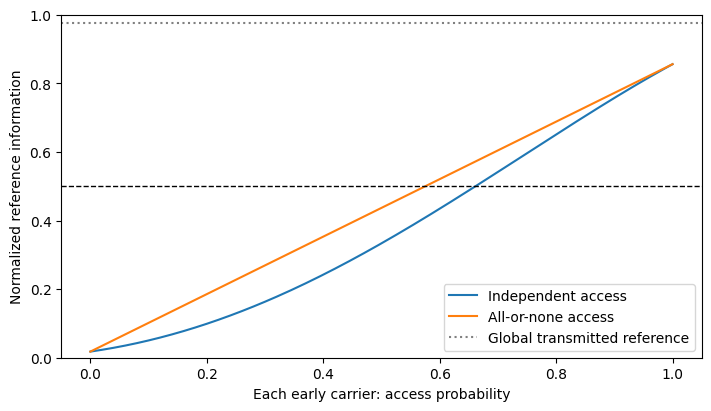

In [3]:
alpha = np.linspace(0,1,201)
weights = np.prod(np.where(bits.T[None,:,:], alpha[:,None,None], 1-alpha[:,None,None]), axis=2)
f = tables[0]
fig, ax = plt.subplots(figsize=(7,4), layout='constrained')
ax.plot(alpha, weights@f, label='Independent access')
ax.plot(alpha, (1-alpha)*f[0]+alpha*f[31], label='All-or-none access')
ax.axhline(e_global[0], color='gray', linestyle=':', label='Global transmitted reference')
ax.axhline(.5, color='black', linestyle='--', linewidth=1)
ax.set(xlabel='Each early carrier: access probability', ylabel='Normalized reference information', ylim=(0,1))
ax.legend(); fig.savefig(OUTPUT/'observer_fixed_state.pdf'); fig.savefig(OUTPUT/'observer_fixed_state.png',dpi=180); plt.show()


## The full attainable range

For each common marginal access probability, linear programs find the smallest and largest information values over all distributions on the 32 joint masks. The mean source table is fixed before optimization, so each endpoint optimizes mean statewise information under a single access law.

The shaded interval displays everything those marginals allow. When the entire interval lies above one half, mean statewise coherent information is positive for every admissible joint access law, even though the information value itself is not uniquely determined.

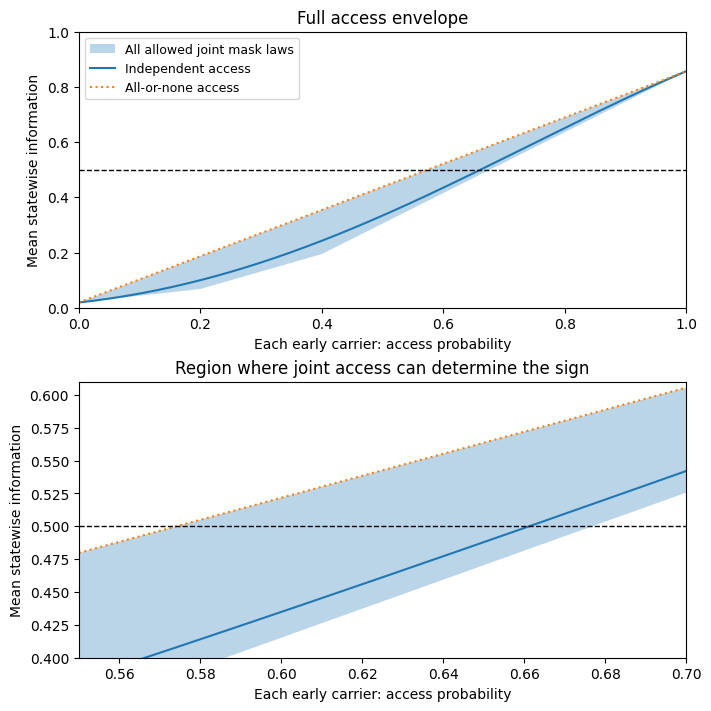

In [4]:
A = np.vstack([np.ones(32), bits]); mean = tables.mean(axis=0)
lo, hi = [], []
for a in alpha:
    b = np.r_[1,np.full(5,a)]
    low = linprog(mean,A_eq=A,b_eq=b,bounds=(0,None),method='highs')
    high = linprog(-mean,A_eq=A,b_eq=b,bounds=(0,None),method='highs')
    assert low.success and high.success
    assert min(low.x.min(),high.x.min()) >= -1e-10
    assert max(np.max(abs(A@low.x-b)),np.max(abs(A@high.x-b))) < 1e-9
    lo.append(low.fun); hi.append(-high.fun)

fig, axs = plt.subplots(2,1,figsize=(7,7),layout='constrained')
for ax in axs:
    ax.fill_between(alpha,lo,hi,alpha=.3,label='All allowed joint mask laws')
    ax.plot(alpha,weights@mean,label='Independent access')
    ax.plot(alpha,(1-alpha)*mean[0]+alpha*mean[31],':',label='All-or-none access')
    ax.axhline(.5,color='black',linestyle='--',linewidth=1)
    ax.set(xlabel='Each early carrier: access probability',ylabel='Mean statewise information')
axs[0].set(title='Full access envelope',xlim=(0,1),ylim=(0,1))
axs[0].legend(fontsize=9)
axs[1].set(title='Region where joint access can determine the sign',xlim=(.55,.70),ylim=(.40,.61))
fig.savefig(OUTPUT/'observer_access_envelope.pdf')
fig.savefig(OUTPUT/'observer_access_envelope.png',dpi=180)
plt.show()


## Attaining access laws and the exact-code comparison

Each linear-program variable is the probability of a particular received mask. The probabilities must be nonnegative, sum to one, and reproduce every specified marginal. The objectives use either the mean statewise Hayden–Preskill table or the five-share code's authorized-set indicator. We display the nonzero probabilities of optimizing distributions so that the endpoints can be checked directly. Multiple distributions can attain the same endpoint.

For the $[[5,1,3]]$ erasure code, any three shares permit recovery, while at most two shares are decorrelated from the reference. Its normalized information is $q=\Pr(K\geq3)$, and its optimal deterministic Bell overlap is $1/4+3q/4$. The correlated collection laws below preserve the carrier marginals. Each specifies its own collection instrument; the independent cavity channel is one such choice.

The two laws rank differently because their weights fall on different subsets of the source's diary correlations. A three-share threshold code has an abrupt authorization threshold. The finite Hayden–Preskill encoding distributes useful correlations across subsets differently. Equal marginal efficiencies do not make either collection law universally preferable.

In [5]:
def extremes(c,m):
    answers=[]
    for sign in [1,-1]:
        fit=linprog(sign*c,A_eq=A,b_eq=np.r_[1,m],bounds=(0,None),method='highs')
        assert fit.success
        assert fit.x.min()>=-1e-10 and np.max(abs(A@fit.x-np.r_[1,m]))<1e-9
        answers.append((float(c@fit.x),fit.x))
    return answers
def root_envelopes(c):
    eq=np.column_stack([A,np.r_[0,-np.ones(5)]])
    answers=[]
    for sign in [1,-1]:
        fit=linprog(np.r_[np.zeros(32),sign],A_ub=[np.r_[-sign*c,0]],b_ub=[-sign*.5],
            A_eq=eq,b_eq=np.r_[1,np.zeros(5)],bounds=[(0,None)]*32+[(0,1)],method='highs')
        assert fit.success and abs(c@fit.x[:32]-.5)<1e-9
        assert np.max(abs(A@fit.x[:32]-np.r_[1,np.full(5,fit.x[-1])]))<1e-9
        answers.append(fit.x[-1])
    return answers
crossings=root_envelopes(mean)
np.testing.assert_allclose(crossings,[.57414868,.67679130],rtol=0,atol=5.1e-9)
state_crossings=np.array([root_envelopes(f) for f in tables])
np.testing.assert_allclose([*state_crossings.min(axis=0),*state_crossings.max(axis=0)],
    [.57289244,.67615167,.57690495,.67888054],rtol=0,atol=5.1e-9)
print('Mean-table first possible / last nonpositive crossings:',crossings)
qec=(bits.sum(axis=0)>=3).astype(float)
witnesses=[]
for model,c,m in [('HP alpha=.6',mean,np.full(5,.6)),('QEC',qec,p)]:
    for label,(value,w) in zip(['minimum','maximum'],extremes(c,m)):
        for mask in np.flatnonzero(w>1e-9):
            witnesses.append([model,label,format(mask,'05b'),w[mask],value])
display(pd.DataFrame(witnesses,columns=['model','endpoint','mask (bit 0 = carrier 1)','probability','information']))
pd.DataFrame(witnesses,columns=['model','endpoint','mask','probability','information']).to_csv(OUTPUT/'attaining_distributions.csv',index=False)
qlo,qhi=[x[0] for x in extremes(qec,p)]
np.testing.assert_allclose([qlo,qhi],[(p.sum()-2)/3,p.sum()/3],rtol=0,atol=1e-12)
np.testing.assert_allclose([qec_value(inputs['global_carriers'][-1]),qec_value(p)],
    [.85665630,.39793071],rtol=0,atol=5.1e-9)
fidelity=.25+.75*np.array([qlo,qhi])
np.testing.assert_allclose(fidelity,[.30641469,.80641469],rtol=0,atol=5.1e-9)
print('QEC information interval:',[qlo,qhi],'fidelity interval:',fidelity)
three=np.where(bits.sum(axis=0)==3,.1,0.)
collective=np.zeros(32); collective[0]=.4; collective[31]=.6
assert np.allclose(bits@three,.6) and np.allclose(bits@collective,.6)
hp_three,hp_collective=tables@three,tables@collective
assert np.all(hp_three<.419) and np.all(hp_collective>.519)
display(pd.DataFrame({'law':['uniform three','all or none'],
    'HP minimum':[hp_three.min(),hp_collective.min()], 'HP maximum':[hp_three.max(),hp_collective.max()],
    'QEC information':[qec@three,qec@collective],
    'QEC optimal Bell overlap':[.25+.75*(qec@three),.25+.75*(qec@collective)]}))
np.testing.assert_allclose([x[0] for x in extremes(mean,np.full(5,.6))],
    [.41521480,.52166286],rtol=0,atol=5.1e-9)
np.testing.assert_allclose([hp_three.min(),hp_three.max(),hp_collective.min()],
    [.41513901,.41883445,.51926692],rtol=0,atol=5.1e-9)
printed_max=.52279603
actual_max=hp_collective.max()
print(f'Collective-access maximum: calculated {actual_max:.12f}; manuscript {printed_max:.8f}; difference {actual_max-printed_max:+.3g}')
assert actual_max>.519  # The stated source-dependent sign reversal still holds.

retention_by_count=[]
for k in range(6):
    values=tables[:,bits.sum(axis=0)==k]
    retention_by_count.append([k,values.min(),values.max()])
display(pd.DataFrame(retention_by_count,columns=['retained early count','minimum over states and masks','maximum over states and masks']))
# Homogeneous five-share polynomial, with exact zero-information branches.
common=np.linspace(0,1,101)
polynomial=10*common**3-15*common**4+6*common**5
assert np.max(abs(polynomial-[qec_value(np.full(5,x)) for x in common]))<1e-13
assert np.all(polynomial[common<.5]<.5) and np.all(polynomial[common>.5]>.5)


Mean-table first possible / last nonpositive crossings: [np.float64(0.5741486821472269), np.float64(0.6767912996869329)]


,model,endpoint,mask (bit 0 = carrier 1),probability,information
0,HP alpha=.6,minimum,00101,0.2666666667,0.4152147986
1,HP alpha=.6,minimum,01010,0.1333333333,0.4152147986
2,HP alpha=.6,minimum,10010,0.1333333333,0.4152147986
3,HP alpha=.6,minimum,11000,0.1333333333,0.4152147986
4,HP alpha=.6,minimum,11111,0.3333333333,0.4152147986
5,HP alpha=.6,maximum,00000,0.4000000000,0.5216628590
6,HP alpha=.6,maximum,11111,0.6000000000,0.5216628590
7,QEC,minimum,00011,0.1742390733,0.0752195907
8,QEC,minimum,00101,0.1786893823,0.0752195907
9,QEC,minimum,01010,0.1976010852,0.0752195907


QEC information interval: [0.0752195906540023, 0.741886257320669] fidelity interval: [0.30641469 0.80641469]


,law,HP minimum,HP maximum,QEC information,QEC optimal Bell overlap
0,uniform three,0.4151390117,0.4188344465,1.0,1.0
1,all or none,0.5192669233,0.5227960241,0.6,0.7


Collective-access maximum: calculated 0.522796024118; manuscript 0.52279603; difference -5.88e-09


,retained early count,minimum over states and masks,maximum over states and masks
0,0,0.0176867791,0.0204119044
1,1,0.0655011027,0.0711121722
2,2,0.1902709959,0.1982327089
3,3,0.4112388721,0.4210870065
4,4,0.6676102408,0.6754970058
5,5,0.8529647831,0.8591748341


### Checking the manuscript's attaining distributions

An LP solver may return a different distribution with the same optimal value. We therefore also check the precise mask weights printed in the observer-proofs appendix. Rounding six probabilities to twelve decimal places can accumulate a marginal error of a few $10^{-12}$; the check allows $3\times10^{-12}$. This verifies the published witnesses independently of which optimizer the solver returns.

In [6]:

printed_lo=np.zeros(32);printed_hi=np.zeros(32)
printed_lo[[3,5,10,20,24,31]]=[.174239073262,.178689382330,.197601085176,.196461471397,.177789397180,.075219590654]
printed_hi[[0,13,19,21,22,26]]=[.258113742679,.292415798090,.133321538019,.002410710138,.155543936153,.158194274921]
for label,w,target in [('minimum',printed_lo,qlo),('maximum',printed_hi,qhi)]:
    residual=np.max(abs(A@w-np.r_[1,p]))
    assert residual<3e-12 and abs(qec@w-target)<3e-12
    print(label,': marginal residual',residual,'; information',qec@w)


minimum : marginal residual 9.999778782798785e-13 ; information 0.075219590654
maximum : marginal residual 4.579669976578771e-13 ; information 0.7418862573210001


Both fixed laws give every carrier marginal access 0.6, yet the two encodings rank them oppositely. The table includes both QEC information and QEC fidelity, so the reversal can be read directly as an information comparison as well.

The calculated collective-access maximum is 0.522796024118. The manuscript's upper endpoint, 0.52279603, rounds outward and remains a valid upper bound.

## A separate detector integration check

Starting from the supplied propagated waveforms, the midpoint exponential recurrence integrates the empty-cavity equation and uses trapezoidal integration for output energies on the $\Delta(t/M)=0.05$ grid. This independently checks the detector calculation. The radial scattering calculation is covered by the upstream notebook.

The recurrence and the primary integrator use different discretizations. Their agreement is assessed against the declared tolerances: $8\times10^{-4}$ for terminal carrier probabilities and $1.5\times10^{-3}$ for decisive supplies. We also check the smaller differences reported in the paper. The table shows this recurrence's discrete balance residuals; the paper's $2.65\times10^{-15}$ balance residual belongs to the reference primary integration.

,carrier,archived,recurrence,absolute_error,discrete_balance_residual
0,1,0.4281480462,0.4281371691,0.0000108771,0.0000102029
1,2,0.4470597491,0.4470482800,0.0000114691,0.0000109928
2,3,0.4503704444,0.4503588682,0.0000115762,0.0000111431
3,4,0.4506100730,0.4505984835,0.0000115895,0.0000111585
4,5,0.4494704592,0.4494588645,0.0000115948,0.0000111428


QEC supply difference: 2.090436490570502e-05


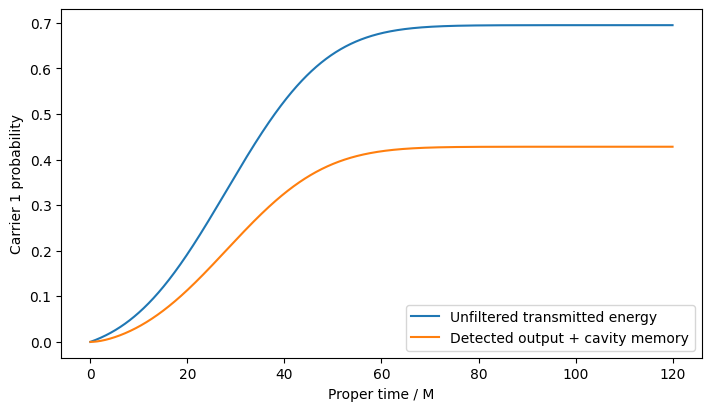

In [7]:
times=inputs['times']
assert np.allclose(np.diff(times),.05) and times[-1]==120
assert abs(float(inputs['eta'])-.6336)<1e-12
assert abs(float(inputs['filter_kappa'])-.515)<1e-12
assert abs(float(inputs['filter_center'])-.16/np.sqrt(.9))<1e-12
G,P,balances=[],[],[]
for j in range(5):
    g,prob,balance=exponential_cavity(times,inputs['envelopes'][:,j],eta=float(inputs['eta']),
        center=float(inputs['filter_center']),kappa=float(inputs['filter_kappa']))
    G.append(g); P.append(prob); balances.append(balance)
G,P=np.array(G).T,np.array(P).T
carrier_error=np.max(abs(P[-1]-p))
qec_error=abs(qec_value(P[-1])-qec_value(p))
assert carrier_error<8e-4 and qec_error<1.5e-3
assert carrier_error<=1.16e-5 and qec_error<=2.10e-5
display(pd.DataFrame({'carrier':np.arange(1,6),'archived':p,'recurrence':P[-1],
    'absolute_error':abs(P[-1]-p),'discrete_balance_residual':balances}))
print('QEC supply difference:',qec_error)
np.savez(OUTPUT/'reintegrated_detector.npz',times=times,global_carriers=G,observer_carriers=P)
fig,ax=plt.subplots(figsize=(7,4),layout='constrained')
ax.plot(times,G[:,0],label='Unfiltered transmitted energy')
ax.plot(times,P[:,0],label='Detected output + cavity memory')
ax.set(xlabel='Proper time / M',ylabel='Carrier 1 probability');ax.legend();plt.show()

## Entropy identities and normalization

The supplied subsystem entropies let us check the direct-sum identity

$$S\!\left(\bigoplus w\rho\right)=H(w)+\sum wS(\rho).$$

We compare the information obtained from this identity with the weighted subset information. These cells use cached entropies; the upstream notebook constructs the source states and recalculates the subsystem entropies directly.

A decorrelated control replaces each joint branch by $I_Q/2\otimes\rho_X$. This preserves the marginal carrier energy and gives zero reference information analytically. The final row checks that cancellation numerically.

In [8]:
entropy_inputs=np.load('inputs/hp_first_seed_entropies.npz')
sx,sqx=entropy_inputs['sx'],entropy_inputs['sqx']
assert np.max(abs((1+sx-sqx)/2-joint[0]))<2e-10
weights2=late_weights[:,None]*mask_weights(np.full(5,.66))[None,:]
positive=weights2[weights2>0]
flag_entropy=-np.sum(positive*np.log2(positive))
S_X=flag_entropy+np.sum(weights2*sx)
S_QX=flag_entropy+np.sum(weights2*sqx)
block_e=(1+S_X-S_QX)/2
subset_e=np.sum(weights2*joint[0])
assert abs(block_e-subset_e)<2e-10
null_e=(1+S_X-(flag_entropy+np.sum(weights2*(1+sx))))/2
assert abs(null_e)<2e-10
display(pd.DataFrame({'quantity':['cached block e','subset e','absolute residual','decorrelated e'],
    'value':[block_e,subset_e,abs(block_e-subset_e),null_e]}))

,quantity,value
0,cached block e,4.9846040301e-01
1,subset e,4.9846040301e-01
2,absolute residual,4.4408920985e-16
3,decorrelated e,0.0000000000e+00


## What can uncertain joint collection still certify?

The detector marginals constrain a family of collection laws. For each source, a linear program maximizes the no-early branch ceiling and minimizes the full-early branch floor over that family. A paired calculation uses one late law for both observers.

To give one obstruction that works for every source, keep the five late probabilities $p_j$ fixed and every early marginal at $\alpha=0.65$. Write $D_5$ and $E_5$ for the complete late and early carrier sets, and set

$$a=\frac{\sum_jp_j-4(1-\alpha)}5.$$

Only seven outcomes have nonzero probability:

$$w_*(\varnothing,E_5)=\alpha-a,\qquad
w_*(D_5,E_5)=a,\qquad
w_*(D_5\setminus\{j\},\varnothing)=a+1-\alpha-p_j.$$

This law is independent of the diary and source label. The next cell displays its weights and verifies normalization and all ten marginals. Mask integers use bit $j-1$ for carrier $j$; flattened arrays put the late mask first and the early mask second.

Let $d_s(z)$ be source $s$'s branch upper certificate for mask $z$, and collect these costs in $\mathsf D$. The law gives a maximum sourcewise certificate of $0.446947387373$, conservatively displayed as **0.4470**. The limiting case is the eleventh source, zero-indexed source 10, with seed 2026082110.

The strongest uniform upper certificate under these marginal constraints is the minimax problem

$$\min_{w,t} t\quad\text{subject to }Aw=b,\quad w\geq0,\quad\mathsf Dw\leq t\mathbf1.$$

Its dual is

$$\max_{y,\lambda} b^{\mathsf T}y\quad\text{subject to }
A^{\mathsf T}y\leq\mathsf D^{\mathsf T}\lambda,\quad
\lambda\geq0,\quad\mathbf1^{\mathsf T}\lambda=1.$$

Here $A$ contains normalization and the ten mask-inclusion rows, $b=(1,p_1,\ldots,p_5,\alpha,\ldots,\alpha)$, and $y$ is unrestricted. Both programs are solved with dual simplex and interior point. The printed dual witness places all source weight on the eleventh source; its eleven equality multipliers are checked directly. A separate checker recomputes the binary-divergence bounds by bisection and verifies every saved primal and dual witness without optimizing.

For comparison, draw a uniform $U$ on $[0,1]$, receive late carrier $j$ when $U<p_j$, and receive all early carriers when $U\geq0.35$. This also meets every marginal and gives the weaker upper certificate **0.4805**.

Finally, imposing probability at least 0.60 for the joint event $K_D\geq2, K_E\geq4$ gives a uniform lower certificate above **0.5190**. All these results bound deterministic recovery with readable flags. Minimax optimality concerns the upper-certificate problem; it does not identify the optimum quantum decoder.


In [9]:
from joint_certificates import evaluate
joint_certification=evaluate(joint,p,OUTPUT/'dependence_witnesses.npz')
display(pd.DataFrame(joint_certification['late_dependence']))
display(pd.DataFrame(joint_certification['joint_repair']))
from minimax_certificates import evaluate as evaluate_minimax, PRINTED_Y
from verify_minimax_results import verify as verify_minimax
minimax=evaluate_minimax(joint,p,OUTPUT/'minimax_witnesses.npz')
_=(OUTPUT/'minimax_obstruction.json').write_text(json.dumps(minimax,indent=2)+'\n',encoding='utf-8')
weights=pd.DataFrame(minimax['law'])
weights.to_csv(OUTPUT/'minimax_seven_outcomes.csv',index=False)
display(weights)
certificates=pd.DataFrame({'source_index':range(len(joint)),
    'seven_outcome_upper':minimax['statewise_upper'],
    'uniform_variable_upper':joint_certification['common_obstruction_statewise_upper']})
certificates.to_csv(OUTPUT/'minimax_statewise_certificates.csv',index=False)
display(certificates)
display(pd.DataFrame({'constraint':['normalization']+[f'late {j}' for j in range(1,6)]+[f'early {j}' for j in range(1,6)],
                      'printed_dual_multiplier':PRINTED_Y}))
display(pd.DataFrame([dict(method='printed witnesses',**minimax['printed_witness']),*minimax['solvers']]))
independent_minimax=verify_minimax(OUTPUT,Path.cwd())
_=(OUTPUT/'minimax_verification.json').write_text(json.dumps(independent_minimax,indent=2)+'\n',encoding='utf-8')
print('Seven-outcome upper certificate:',minimax['upper_certificate'],'; conservative bound: 0.4470')
print('Limiting source (one-based):',minimax['limiting_source_ordinal'])
print('Independent witness-check maximum residual:',independent_minimax['maximum_raw_residual'])
print('Uniform-variable comparison:',joint_certification['common_obstruction_upper'])
_=(OUTPUT/'joint_certification.json').write_text(json.dumps(joint_certification,indent=2)+'\n',encoding='utf-8')


,source_index,no_early_upper,full_early_lower,paired_advantage_lower,maximum_LP_residual
0,0,0.4375153449,0.5867305500,0.1492152051,1.1102230246e-16
1,1,0.4397284329,0.5870737556,0.1473459943,1.1102230246e-16
2,2,0.4440154925,0.5868091039,0.1427936114,5.5511151231e-17
3,3,0.4386671721,0.5872370768,0.1485699047,1.1102230246e-16
4,4,0.4409616287,0.5872494843,0.1462878556,5.5511151231e-17
5,5,0.4388342283,0.5871970183,0.1483627900,1.1102230246e-16
6,6,0.4418533714,0.5867803382,0.1449269668,1.1102230246e-16
7,7,0.4400700585,0.5873632479,0.1472931894,1.1102230246e-16
8,8,0.4361912930,0.5872173179,0.1510260249,1.1102230246e-16
9,9,0.4425010003,0.5875257915,0.1450247913,5.5511151231e-17


,source_index,repaired_lower,joint_event_probability,maximum_LP_residual
0,0,0.5194361206,0.6,4.4408920985e-16
1,1,0.5195710356,0.6,5.5511151231e-16
2,2,0.5193252104,0.6,5.5511151231e-16
3,3,0.5193947620,0.6,4.4408920985e-16
4,4,0.5216774718,0.6,1.2212453271e-15
5,5,0.5192693632,0.6,2.1094237468e-15
6,6,0.5191845256,0.6,5.5511151231e-16
7,7,0.5205809569,0.6,1.1102230246e-15
8,8,0.5202490107,0.6,1.2212453271e-15
9,9,0.5192122221,0.6,6.6613381478e-16


,late_mask,early_mask,probability
0,0,31,0.4848682456
1,15,0,0.0656612952
2,23,0,0.0645216814
3,27,0,0.0647613100
4,29,0,0.0680720053
5,30,0,0.0869837081
6,31,31,0.1651317544


,source_index,seven_outcome_upper,uniform_variable_upper
0,0,0.4429387478,0.4753970352
1,1,0.4442539075,0.4771380344
2,2,0.4467192676,0.4804810204
3,3,0.4447831289,0.4762870695
4,4,0.4459660748,0.4780521899
5,5,0.4439604517,0.4763742615
6,6,0.4454059151,0.4788642328
7,7,0.4456515292,0.4774428604
8,8,0.4430812349,0.4743609619
9,9,0.4462981706,0.4793262214


,constraint,printed_dual_multiplier
0,normalization,-0.1407256971
1,late 1,0.1544959204
2,late 2,0.1540769327
3,late 3,0.1497391423
4,late 4,0.1436419033
5,late 5,0.1479698744
6,early 1,0.1353951687
7,early 2,0.1295628119
8,early 3,0.1233826974
9,early 4,0.0005830649


,method,primal_value,dual_value,residuals
0,printed witnesses,0.4469473874,0.4469473874,"{'marginal_linf': 2.220446049250313e-16, 'prim..."
1,highs-ds,0.4469473874,0.4469473874,"{'marginal_linf': 5.440092820663267e-15, 'prim..."
2,highs-ipm,0.4469473874,0.4469473874,"{'marginal_linf': 1.1102230246251565e-16, 'pri..."


Seven-outcome upper certificate: 0.4469473873729411 ; conservative bound: 0.4470
Limiting source (one-based): 11
Independent witness-check maximum residual: 5.440092820663267e-15
Uniform-variable comparison: 0.48048102040658347


### Which collection event gives the most useful certificate?

An observed event rate can certify a recovery bound even when the true mask is not read perfectly. For each source, maximize that rate over all compatible laws whose branchwise lower certificate is at most one half. A population rate above the largest sourcewise threshold excludes every such law.

The candidate class is declared before calculation: all 25 conjunctions $\{K_D\geq a,K_E\geq b\}$ with $a,b\in\{1,\ldots,5\}$, and the ten total-count events $\{K_D+K_E\geq k\}$ with $k\in\{1,\ldots,10\}$. The all-ten event duplicates the conjunction $(5,5)$, leaving 34 distinct indicators. The catalog below lists every event and its complete ranking.

For each event, certification headroom is its largest feasible population probability minus its worst-source uncertified threshold. For ranking only, headroom within $10^{-8}$ of zero is tied and ordered by event name; raw values remain unchanged. Rank all events on the full source family, then separately on even and odd zero-based source indices. These splits assess sensitivity within the frozen family; they do not establish optimality outside the declared class.

Evaluate both clean flags and independent symmetric flag flips with probability 0.02. Conditional count probabilities define the noisy event score. Every LP uses primal and dual feasibility tolerances of $10^{-8}$. Direct lower-certificate minimization checks feasible rates $10^{-6}$ above the full-family threshold. The selected event also receives an interior-point versus dual-simplex comparison and direct checks at the displayed sufficient rates. Primal laws, dual multipliers, unrounded thresholds, and raw residuals are saved.

These are population-probability certificates. Finite-shot use additionally needs a valid lower confidence bound and a trial-dependence model.

In [10]:
from event_certificates import search
frontiers=[]
for epsilon in [0.,.02]:
    result=search(joint,p,epsilon,OUTPUT/f'event_witnesses_{epsilon:.2f}.npz')
    frontiers.append(result)
    rows=[]
    for item in result['catalog']:
        rows.append(dict(event=item['event'],feasible_maximum=item['feasible_maximum'],
                         **{f'{split}_{key}':value for split,values in item['splits'].items() for key,value in values.items()}))
    ranking=pd.DataFrame(rows).set_index('event').loc[result['rankings']['all']].reset_index()
    ranking.to_csv(OUTPUT/f'event_ranking_{epsilon:.2f}.csv',index=False)
    print('Flag-flip probability:',epsilon,'; selections:',{k:v[0] for k,v in result['rankings'].items()})
    display(ranking)
    assert all(r[0]=='E7' for r in result['rankings'].values())
    selected=next(x for x in result['catalog'] if x['event']=='E7')
    target=.37586003 if epsilon==0 else .34094225
    assert abs(selected['splits']['all']['threshold']-target)<5.1e-9
_=(OUTPUT/'count_event_frontiers.json').write_text(json.dumps(frontiers,indent=2)+'\n',encoding='utf-8')


Flag-flip probability: 0.0 ; selections: {'all': 'E7', 'even': 'E7', 'odd': 'E7'}


,event,feasible_maximum,all_threshold,all_headroom,even_threshold,even_headroom,odd_threshold,odd_headroom
0,E7,0.7822369674,0.3758600290,4.0637693844e-01,0.3749447878,4.0729217962e-01,0.3758600290,4.0637693844e-01
1,D3_E4,0.7418862573,0.3727104658,3.6917579153e-01,0.3715664629,3.7031979444e-01,0.3727104658,3.6917579153e-01
2,E8,0.6844573465,0.3430387812,3.4141856531e-01,0.3426919383,3.4176540816e-01,0.3430387812,3.4141856531e-01
3,E6,0.9126097953,0.5792704869,3.3333930841e-01,0.5780320928,3.3457770249e-01,0.5792704869,3.3333930841e-01
4,D3_E5,0.6500000000,0.3416219248,3.0837807522e-01,0.3416219248,3.0837807522e-01,0.3411222615,3.0887773846e-01
5,D2_E5,0.6500000000,0.3664742001,2.8352579987e-01,0.3664742001,2.8352579987e-01,0.3664233606,2.8357663939e-01
6,D2_E4,0.8125000000,0.5395168068,2.7298319322e-01,0.5395056321,2.7299436793e-01,0.5395168068,2.7298319322e-01
7,D4_E5,0.5564146930,0.3351734260,2.2124126695e-01,0.3351734260,2.2124126695e-01,0.3350820147,2.2133267831e-01
8,E9,0.5564146930,0.3354567636,2.2095792938e-01,0.3354567636,2.2095792938e-01,0.3353106990,2.2110399401e-01
9,D4_E4,0.5564146930,0.3427113804,2.1370331258e-01,0.3424674636,2.1394722943e-01,0.3427113804,2.1370331258e-01


Flag-flip probability: 0.02 ; selections: {'all': 'E7', 'even': 'E7', 'odd': 'E7'}


,event,feasible_maximum,all_threshold,all_headroom,even_threshold,even_headroom,odd_threshold,odd_headroom
0,E7,0.6847919656,0.3409422505,3.4384971512e-01,0.3406458844,3.4414608114e-01,0.3409422505,3.4384971512e-01
1,D3_E4,0.6659290509,0.3332358947,3.3269315618e-01,0.3332358947,3.3269315618e-01,0.3331705462,3.3275850472e-01
2,E6,0.8161251117,0.5494339456,2.6669116612e-01,0.5487555247,2.6736958705e-01,0.5494339456,2.6669116612e-01
3,D2_E5,0.5871559435,0.3209359335,2.6622001004e-01,0.3209359335,2.6622001004e-01,0.3208930115,2.6626293198e-01
4,D3_E5,0.5678509690,0.3023806515,2.6547031746e-01,0.3023806515,2.6547031746e-01,0.3023214075,2.6552956152e-01
5,E8,0.5926486597,0.3336792927,2.5896936701e-01,0.3336435417,2.5900511801e-01,0.3336792927,2.5896936701e-01
6,D2_E4,0.7427174538,0.4856631561,2.5705429773e-01,0.4856536253,2.5706382855e-01,0.4856631561,2.5705429773e-01
7,D3_E3,0.6989372019,0.5106786228,1.8825857907e-01,0.5103304731,1.8860672882e-01,0.5106786228,1.8825857907e-01
8,D4_E4,0.5120819841,0.3313844740,1.8069751009e-01,0.3313489641,1.8073302002e-01,0.3313844740,1.8069751009e-01
9,D4_E3,0.5140173206,0.3334027687,1.8061455192e-01,0.3334027687,1.8061455192e-01,0.3332549480,1.8076237259e-01


## Reading the results

The seven-outcome law has maximum sourcewise upper certificate 0.446947387373, below the conservative bound 0.4470. Its primal and dual witnesses establish numerical minimax optimality for the upper certificate. The uniform-variable law gives 0.48048102040658347 under the same marginals. The joint-count constraint raises the uniform lower certificate to 0.5190306127037225.

Among the 34 declared events, $E_7$ has the greatest headroom on the full family and on both source splits. Its clean threshold is 0.375860028988, with feasible maximum 0.782236967423. Under 2% independent flag flips, the threshold is 0.340942250453 and the feasible maximum is 0.684791965576. The respective conservative sufficient rates, 0.3759 and 0.3410, pass direct lower-certificate checks. These comparisons concern the specified event class and frozen sources.

For the specified radiation states, early-radiation access changes the bounds on deterministic recovery while the source and late detector stay fixed. Joint access also changes what can be recovered: identical carrier marginals allow different information values, and two encodings can rank the same collection laws oppositely.

The [upstream notebook](Upstream_Regeneration.ipynb) follows the same question from source preparation through scattering and detection. Here, the recovery bounds show why possession of early radiation and the joint collection law are physical parts of the recovery problem.